# 作业3：NumPy、Matplotlib 与 pandas

作答：罗文希；学号：20244081107。题目作者：丁平尖。

注意事项：尽早开始，提前发现安装或导入问题；备份工作，推荐使用 Git；将第一个代码框的学号改为自己的学号，再按顺序运行。

在 PyCharm 或 VS Code 中编辑，Notebook 命名为 `20244081107_罗文希_hw03.ipynb`；另须提交本题生成的 `iris_corrected.csv`。

## 身份与环境记录

In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244081107

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] ALICE
[学号]       20244081107
[机器指纹] c13bd608a3df89c7
[RUN_ID]   20244081107-c13bd608a3df89c7


解题说明：使用 Python (ALICE)，工作目录为 HW03；随机实验固定种子 20244081107。

In [2]:
import sys
from pathlib import Path
print("解释器：", sys.executable)
print("工作目录：", Path.cwd())
assert Path(sys.executable).parent.name == "ALICE"
assert CONDA_ENV == "ALICE"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
rng = np.random.default_rng(20244081107)

解释器： Z:\Anaconda\anaconda\envs\ALICE\python.exe
工作目录： L:\26年秋季\Python_Data_Processing\HW03


## 围绕半圆定律

随机矩阵理论研究随机矩阵的性质。对于下述随机对称矩阵，随着矩阵阶数 $n$ 增大，其特征值的分布趋近于半圆定律。半圆密度为

$$f(x)=\begin{cases}\frac{1}{2\pi}\sqrt{4-x^2}, & |x|\le 2,\\0,&|x|>2.\end{cases}$$

构造 $n\times n$ 的对称随机矩阵 $Z$：对所有 $1\le i\le j\le n$，独立地从均值为 $0$、方差为 $1/n$ 的正态分布抽取 $Z_{ij}$，再令 $Z_{ji}=Z_{ij}$。这样的矩阵称为 Wigner 矩阵。其特征值的标准化直方图会随 $n$ 增大而逐渐接近上述密度曲线。

### 1. 半圆密度

编写 `wigner_density(x)`，接收一个整数或浮点数，返回半圆密度在 $x$ 处的值，返回值为浮点数。不需要检查输入类型；函数应同时适用于 Python 和 NumPy 的整数、浮点数。计算平方根时使用 `numpy.sqrt`，不要使用 `math.sqrt`。

In [3]:
def wigner_density(x):
    if abs(x) > 2:
        return 0.0
    return float(np.sqrt(4 - x * x) / (2 * np.pi))

for x in [-3, -2, 0, 1.5, 2, np.int64(1), np.float64(0.5)]:
    value = wigner_density(x)
    print(f"x={x}: {value}, 类型={type(value).__name__}")
    assert type(value) is float
assert np.isclose(wigner_density(0), 1 / np.pi)
assert wigner_density(-2) == wigner_density(2) == wigner_density(3) == 0.0

x=-3: 0.0, 类型=float
x=-2: 0.0, 类型=float
x=0: 0.3183098861837907, 类型=float
x=1.5: 0.2105421996738962, 类型=float
x=2: 0.0, 类型=float
x=1: 0.27566444771089604, 类型=float
x=0.5: 0.30820222203074993, 类型=float


### 2. 随机 Wigner 矩阵

编写 `generate_wigner(n)`，接收正整数 $n$，返回一个随机生成的 $n\times n$ Wigner 矩阵，可以使用 NumPy 的二维数组或矩阵表示。若输入不是整数或不是正数，应抛出合适的异常。

In [4]:
def generate_wigner(n):
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须为正数")
    rows, cols = np.triu_indices(n)
    matrix = np.zeros((n, n))
    matrix[rows, cols] = rng.normal(0, 1 / np.sqrt(n), size=len(rows))
    matrix[cols, rows] = matrix[rows, cols]
    return matrix

example_matrix = generate_wigner(4)
print(example_matrix)
assert example_matrix.shape == (4, 4)
assert np.array_equal(example_matrix, example_matrix.T)
print("n=1:", generate_wigner(np.int64(1)))
for bad_n in [0, -1, 2.5, True]:
    try:
        generate_wigner(bad_n)
    except (TypeError, ValueError) as exc:
        print(repr(bad_n), type(exc).__name__, str(exc))

[[ 0.52221731  0.2110782   0.00855276  0.21956175]
 [ 0.2110782   0.08015898 -0.26060642  0.20068423]
 [ 0.00855276 -0.26060642  0.35951881 -0.47958506]
 [ 0.21956175  0.20068423 -0.47958506 -0.43213458]]
n=1: [[0.35364842]]
0 ValueError n 必须为正数
-1 ValueError n 必须为正数
2.5 TypeError n 必须是整数
True TypeError n 必须是整数


**结果说明：** 上三角（含对角线）独立抽样，复制到下三角；正态分布参数使用标准差 $1/\sqrt{n}$。非整数抛出 TypeError，非正整数抛出 ValueError，布尔值不视为矩阵阶数。

### 3. 特征值

编写 `get_spectrum(matrix)`，接收 NumPy 矩阵或二维 NumPy 数组，返回包含其全部特征值的 NumPy 数组，按非递减顺序排列。本函数不需要检查输入类型。

In [5]:
def get_spectrum(matrix):
    return np.sort(np.real_if_close(np.linalg.eigvals(matrix)))

spectrum = get_spectrum(example_matrix)
print("第2题示例矩阵的谱：", spectrum)
assert isinstance(spectrum, np.ndarray)
assert len(spectrum) == 4
assert np.all(np.diff(spectrum) >= 0)
assert np.allclose(spectrum, np.linalg.eigvalsh(example_matrix))
assert np.allclose(get_spectrum(np.array([[2, 1], [1, 2]])), [1, 3])

第2题示例矩阵的谱： [-0.69419916 -0.11410207  0.48593732  0.85212443]


**结果说明：** 复用第2题的 example_matrix。函数使用通用特征值 API，可接收二维数组；本大题的实对称矩阵具有实特征值。一般非对称矩阵可能有复特征值，此时非递减的实数顺序不适用。

### 4. 绘图与比较

画一张包含四个纵向排列子图的图。对 $n=100,200,500,1000$，每个子图分别用蓝色、标准化的直方图展示随机 $n\times n$ Wigner 矩阵的特征值，并叠加红色的半圆密度曲线。根据图形说明：$n$ 大约达到多少时，半圆密度能较好地拟合特征值分布？使用 Kolmogorov–Smirnov 检验作更严格的比较是可选任务。特征值计算可能较慢，尤其是远大于 1000 阶的矩阵。

n=100: min=-1.8677, max=1.9206


n=200: min=-1.9459, max=2.0646

n=500: min=-1.9431, max=1.9745


n=1000: min=-2.0116, max=1.9720


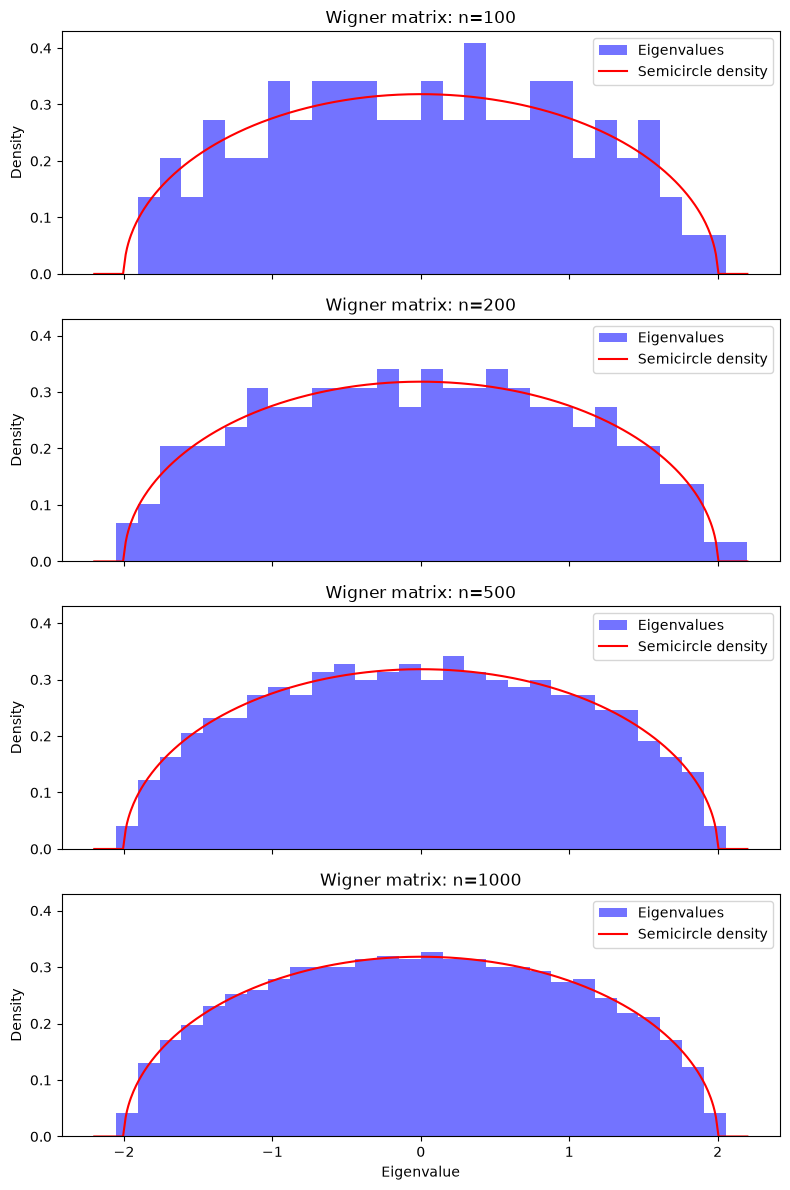

In [6]:
# 复用第1、2、3题函数；本题单独重置种子以复现四组随机矩阵。
rng = np.random.default_rng(20244081107)
x_grid = np.linspace(-2.2, 2.2, 500)
y_grid = [wigner_density(x) for x in x_grid]
fig, axes = plt.subplots(4, 1, figsize=(8, 12), sharex=True, sharey=True)
for ax, size in zip(axes, [100, 200, 500, 1000]):
    eigenvalues = get_spectrum(generate_wigner(size))
    heights, edges, _ = ax.hist(eigenvalues, bins=np.linspace(-2.2, 2.2, 31),
                                density=True, color="blue", alpha=0.55, label="Eigenvalues")
    ax.plot(x_grid, y_grid, color="red", label="Semicircle density")
    ax.set_title(f"Wigner matrix: n={size}")
    ax.set_ylabel("Density")
    ax.legend(loc="upper right")
    assert np.isclose(np.sum(heights * np.diff(edges)), 1)
    print(f"n={size}: min={eigenvalues.min():.4f}, max={eigenvalues.max():.4f}")
axes[-1].set_xlabel("Eigenvalue")
fig.tight_layout()
plt.show()

**结果说明：** 在本次固定种子、相同分箱下，n=100 时柱高波动较明显，n=200 已能看出半圆轮廓；n 约达到500时，直方图与理论密度已较好贴合，n=1000时更平滑。这是对本次图形的经验判断，受随机样本与分箱影响，不是普适的阶数阈值。标准化直方图面积为1，与概率密度曲线可直接比较；本题未执行可选 KS 检验。

## Conway 的生命游戏

生命游戏在一个 $m\times n$ 棋盘上进行，棋盘用 NumPy 的二维数组表示：活细胞记为 1，死细胞记为 0。每一步按以下规则**同时更新**所有细胞：

- 活细胞有少于两个活邻居时死亡；
- 活细胞有两个或三个活邻居时继续存活；
- 活细胞有多于三个活邻居时死亡；
- 死细胞恰好有三个活邻居时复活；
- 其他死细胞保持死亡。

每个细胞有上、下、左、右和四个对角方向的邻居，共八个。棋盘采用环绕边界：例如，位置 `(0, 0)` 上方的邻居是 `(m-1, 0)`，位置 `(m-1, n-1)` 右侧的邻居是 `(m-1, 0)`。

### 1. 棋盘有效性

编写 `is_valid_board(board)`，接收一个 NumPy ndarray，若它是有效的生命游戏棋盘（二维、元素仅为 0 或 1）则返回 Python 布尔值 True，否则返回 False。

In [7]:
def is_valid_board(board):
    return bool(isinstance(board, np.ndarray) and board.ndim == 2
                and np.all((board == 0) | (board == 1)))

for board in [np.array([[0, 1], [1, 0]]), np.array([0, 1]),
              np.array([[0, 2]]), [[0, 1]], np.array([[np.nan]])]:
    result = is_valid_board(board)
    print(repr(board), "->", result)
    assert type(result) is bool
assert is_valid_board(np.array([[True, False]]))

array([[0, 1],
       [1, 0]]) -> True
array([0, 1]) -> False
array([[0, 2]]) -> False
[[0, 1]] -> False
array([[nan]]) -> False


### 2. 同步更新

编写 `gol_step(board)`，接收一个 $m\times n$ 棋盘，返回同样大小的 NumPy 数组，表示下一步的棋盘。函数应先检查输入是否为有效棋盘，无效时抛出合适的异常。计算某个细胞的下一状态时，应使用原棋盘中的邻居状态。

In [8]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("棋盘必须是二维 ndarray，且元素仅为0或1")
    neighbors = np.zeros(board.shape, dtype=int)
    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            if dr != 0 or dc != 0:
                neighbors += np.roll(board, (dr, dc), axis=(0, 1)).astype(int)
    return ((neighbors == 3) | ((board == 1) & (neighbors == 2))).astype(int)

blinker = np.zeros((5, 5), dtype=int)
blinker[2, 1:4] = 1
original = blinker.copy()
next_board = gol_step(blinker)
expected = np.zeros((5, 5), dtype=int)
expected[1:4, 2] = 1
print("初始：\n", blinker, "\n下一步：\n", next_board)
assert np.array_equal(next_board, expected)
assert np.array_equal(gol_step(next_board), blinker)
assert np.array_equal(blinker, original)
block = np.zeros((6, 6), dtype=int)
block[2:4, 2:4] = 1
assert np.array_equal(gol_step(block), block)
wrapped = np.zeros((5, 5), dtype=int)
wrapped[0, [4, 0, 1]] = 1
wrapped_expected = np.zeros((5, 5), dtype=int)
wrapped_expected[[4, 0, 1], 0] = 1
print("环绕边界下一步：\n", gol_step(wrapped))
assert np.array_equal(gol_step(wrapped), wrapped_expected)
try:
    gol_step(np.array([[2]]))
except ValueError as exc:
    print(type(exc).__name__, str(exc))

初始：
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]] 
下一步：
 [[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
环绕边界下一步：
 [[1 0 0 0 0]
 [1 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [1 0 0 0 0]]
ValueError 棋盘必须是二维 ndarray，且元素仅为0或1


**结果说明：** 复用第1题验证函数。np.roll 实现八个方向的环绕移动，先由原棋盘计算全部邻居数，再一次性生成新棋盘。振荡器两步恢复原状，方块保持不变，跨边界振荡器也正确更新；原输入未被修改。对于维度小于3的棋盘，按八个方向分别计数，环绕后可能重复指向同一格。

### 3. 绘制棋盘

编写 `draw_gol_board(board)`，将棋盘画成 $m\times n$ 个方格：活细胞为黑色，死细胞为白色。图中不显示网格线、轴标签或轴刻度。可以使用 `plt.xticks()`、`plt.yticks()` 和 `plt.get_cmap()` 等函数。

初始棋盘


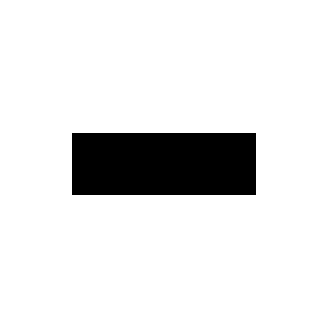

下一步棋盘


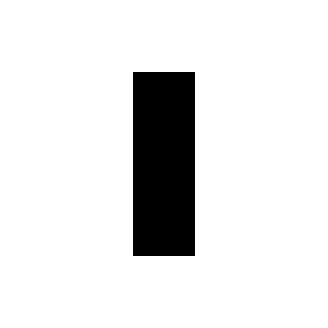

In [9]:
def draw_gol_board(board):
    plt.figure(figsize=(4, 4))
    plt.imshow(board, cmap=plt.get_cmap("binary"), vmin=0, vmax=1,
               interpolation="nearest", aspect="equal")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.axis("off")
    plt.show()

# 复用第2题的初始棋盘与下一步棋盘，依次展示。
print("初始棋盘")
draw_gol_board(blinker)
print("下一步棋盘")
draw_gol_board(next_board)

**结果说明：** binary 色图将 0 映射为白色、1 映射为黑色；等比例显示使每个细胞呈正方形。

## 使用 pandas DataFrame

本题练习读取、修改和保存 DataFrame，以及按组汇总数据。

**解题说明（数据来源与衔接）：** CSV 来自题目指定的 [Kaggle 数据集](https://www.kaggle.com/datasets/gradylynn/iris-csv)，原文件只有索引和四项测量。参考数据集作者的 [示例 Notebook](https://www.kaggle.com/code/gradylynn/grady-is-the-best-teacher-ever)，第1题先用 pandas 读取 CSV，再从 scikit-learn 的 `load_iris()` 取得标签，以 `target_names[target]` 转成花卉名称，补入工作副本的 `Species` 列，然后回答数据点数、列名、类型和种类数。

标签按原始行顺序对应，不按测量值预测种类。补入前核对150行与原始索引，并逐项比较四项测量；CSV 中已有的缺失值和异常值仅展示，不用参考数据覆盖。后题继续使用这个工作副本。其余 CSV 清洗问题按此前约定留待后续解决。

### 1. 读取与检查

下载 `iris.csv`（https://www.kaggle.com/datasets/gradylynn/iris-csv）。使用 pandas 将它读入为 DataFrame；CSV 的第一行是列标题。回答：数据集有多少个数据点？每列是什么数据类型？列名是什么？数据中有多少种花卉？列名对应花卉种类，以及花瓣长度、花瓣宽度、萼片长度和萼片宽度四项测量。

In [10]:
csv_path = Path("iris.csv")
if not csv_path.exists():
    csv_path = Path("archive/iris.csv")
print("CSV:", csv_path)
raw_iris = pd.read_csv(csv_path, encoding="utf-8")
print("原文件数据点数：", len(raw_iris))
print("原文件列名：", raw_iris.columns.tolist())
print("原文件类型：\n", raw_iris.dtypes)
display(raw_iris.head())

# 保留原文件和原始 DataFrame，仅对工作副本统一列名。
column_aliases = {
    "sepallength": "Sepal.Length", "sepalwidth": "Sepal.Width",
    "petallength": "Petal.Length", "petalwidth": "Petal.Width",
    "species": "Species", "variety": "Species", "class": "Species",
}
def normalize_column(name):
    key = str(name).lower().replace("(cm)", "")
    key = "".join(ch for ch in key if ch.isalnum())
    return column_aliases.get(key, name)

iris = raw_iris.rename(columns=normalize_column).copy()
index_columns = [name for name in iris.columns if str(name).startswith("Unnamed:")]
iris = iris.drop(columns=index_columns)
measurements = ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width"]
assert set(measurements).issubset(iris.columns), "请核对四项测量列名"
# CSV 缺少种类列：沿用数据集作者的方法，从 sklearn 补入标签。
from sklearn.datasets import load_iris

iris_dataset = load_iris()
if "Species" not in iris.columns:
    assert len(iris) == len(iris_dataset.target), "CSV 行数必须与参考 Iris 数据一致"
    if index_columns:
        assert len(index_columns) == 1
        assert np.array_equal(raw_iris[index_columns[0]].to_numpy(),
                              np.arange(len(iris))), "原始索引顺序已改变，不能直接按行补标签"
    csv_values = iris[measurements].to_numpy(dtype=float)
    reference_values = iris_dataset.data
    matching = np.isclose(csv_values, reference_values, equal_nan=False)
    differences = pd.DataFrame({
        "行索引": np.repeat(np.arange(len(iris)), len(measurements)),
        "测量列": np.tile(measurements, len(iris)),
        "CSV值": csv_values.ravel(),
        "参考值": reference_values.ravel(),
    })
    print("与参考数据逐项核对：", int(matching.sum()), "/", matching.size, "项一致")
    print("缺失或不同的测量值（仅展示，不修改）：")
    display(differences.loc[~matching.ravel()].reset_index(drop=True))
    iris["Species"] = iris_dataset.target_names[iris_dataset.target]
    assert np.array_equal(iris["Species"].to_numpy(),
                          iris_dataset.target_names[iris_dataset.target])

has_species = "Species" in iris.columns
print("补入标签后的数据点数：", len(iris))
print("补入标签后的列名：", iris.columns.tolist())
print("补入标签后的各列类型：\n", iris.dtypes)
print("花卉种类数：", iris["Species"].nunique())
print("每种花卉的数量：")
display(iris["Species"].value_counts())
display(iris.head())
print("原始 CSV 缺失值数量：")
display(raw_iris.isna().sum())

CSV: archive\iris.csv
原文件数据点数： 150
原文件列名： ['Unnamed: 0', 'sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
原文件类型：
 Unnamed: 0             int64
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
dtype: object


,Unnamed: 0,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,0,5.1,3.5,1.4,0.2
1,1,4.9,3.0,1.4,0.2
2,2,4.7,3.2,1.3,0.2
3,3,4.6,3.1,1.5,0.2
4,4,5.0,3.6,1.4,0.2


与参考数据逐项核对： 596 / 600 项一致
缺失或不同的测量值（仅展示，不修改）：


,行索引,测量列,CSV值,参考值
0,24,Sepal.Length,NaN,4.8
1,37,Petal.Length,NaN,1.4
2,50,Petal.Width,14.0,1.4
3,56,Sepal.Width,NaN,3.3


补入标签后的数据点数： 150
补入标签后的列名： ['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width', 'Species']
补入标签后的各列类型：
 Sepal.Length    float64
Sepal.Width     float64
Petal.Length    float64
Petal.Width     float64
Species             str
dtype: object
花卉种类数： 3
每种花卉的数量：


Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


原始 CSV 缺失值数量：


Unnamed: 0           0
sepal length (cm)    1
sepal width (cm)     1
petal length (cm)    1
petal width (cm)     0
dtype: int64

**结果说明：** 共有150个数据点。原始 CSV 的 `Unnamed: 0` 为 int64 索引列，其余四列为 float64 测量值；原列名见上方输出。工作副本去掉冗余索引，统一四项测量列名为 `Sepal.Length`、`Sepal.Width`、`Petal.Length`、`Petal.Width`，分别对应萼片长度、萼片宽度、花瓣长度、花瓣宽度，类型均为 float64。读取后额外补入 `Species` 字符串列，其实际 pandas 类型见输出。补入的标签给出3种花卉：setosa、versicolor、virginica，各50条。种类信息来自 scikit-learn，原始 CSV 文件保持不变。

**行顺序说明：** 此处沿用数据集作者按原始 Iris 行顺序补标签的约定，先核对行数及0至149的原始索引，再展示测量值对照。对照中的少量缺失和异常值说明此 CSV 是经过改动的教学版本，不应直接把它当成完整、干净的参考数据。

### 2. 更正数据行

已知数据的第 35 个和第 38 个数据行有误（不计列标题）。将第 35 行改为 `4.9,3.1,1.5,0.2,"setosa"`，其中原文件的第四项测量有误；将第 38 行改为 `4.9,3.6,1.4,0.1,"setosa"`，其中原文件的第二、三项测量有误。请在 DataFrame 中完成修改，并检查修改后的两行。若采用从 0 开始的默认行索引，这两行的索引分别是 34 和 37。

In [11]:
# 延续第1题的工作副本，按列名定位，避免把 CSV 的索引列当成测量值。
print("更正前：")
display(iris.loc[[34, 37]])
corrections = [[4.9, 3.1, 1.5, 0.2], [4.9, 3.6, 1.4, 0.1]]
iris.loc[[34, 37], measurements] = corrections
if has_species:
    iris.loc[[34, 37], "Species"] = "setosa"
else:
    print("当前仅更正四项测量；完整种类列待补充，不用两个标签代替完整数据。")
print("更正后：")
display(iris.loc[[34, 37]])
assert np.allclose(iris.loc[[34, 37], measurements].to_numpy(dtype=float), corrections)
if has_species:
    assert iris.loc[[34, 37], "Species"].eq("setosa").all()

更正前：


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
34,4.9,3.1,1.5,0.2,setosa
37,4.9,3.6,NaN,0.1,setosa


更正后：


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
34,4.9,3.1,1.5,0.2,setosa
37,4.9,3.6,1.4,0.1,setosa


**结果说明：** 第35个数据行对应索引34，第38个对应索引37。当前文件第35行已符合给定值，第38行花瓣长度缺失；赋值后两行均满足题目要求。文件中另外两处测量缺失值不在题目指定的更正范围，保留原状，待后续解决 CSV 问题。Species 沿用第1题从 scikit-learn 补入的标签，本题将两行种类按题目要求设为 setosa。

### 3. 新增比例特征

添加两列新特征：`Petal.Ratio` 为花瓣长度除以花瓣宽度；`Sepal.Ratio` 为萼片长度除以萼片宽度。

In [12]:
# 使用第2题更正后的 iris，不重新读取原文件。
iris["Petal.Ratio"] = iris["Petal.Length"] / iris["Petal.Width"]
iris["Sepal.Ratio"] = iris["Sepal.Length"] / iris["Sepal.Width"]
display(iris.head())
for part in ["Petal", "Sepal"]:
    length = iris[f"{part}.Length"]
    width = iris[f"{part}.Width"]
    ratio = iris[f"{part}.Ratio"]
    valid = length.notna() & width.notna()
    assert np.allclose(ratio[valid] * width[valid], length[valid])
    assert ratio[~valid].isna().all()
print("比例列缺失值：")
display(iris[["Petal.Ratio", "Sepal.Ratio"]].isna().sum())

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species,Petal.Ratio,Sepal.Ratio
0,5.1,3.5,1.4,0.2,setosa,7.0,1.457143
1,4.9,3.0,1.4,0.2,setosa,7.0,1.633333
2,4.7,3.2,1.3,0.2,setosa,6.5,1.468750
3,4.6,3.1,1.5,0.2,setosa,7.5,1.483871
4,5.0,3.6,1.4,0.2,setosa,7.0,1.388889


比例列缺失值：


Petal.Ratio    0
Sepal.Ratio    2
dtype: int64

**结果说明：** 两个比例均由同一行的相应长度除以宽度，沿用前题更正后的数据。当前数据中的非缺失宽度均非零；缺失测量会传播为比例缺失值，验证在测量完整的行核对乘积，并检查其余行的比例为缺失值，不擅自填补。

### 4. 保存提交数据

将更正并扩展后的 DataFrame 保存为 `iris_corrected.csv`，并随作业提交。

In [13]:
# 只有完整种类列存在且无缺失时，才生成符合题意的提交数据。
data_ready = has_species and iris[measurements + ["Species"]].notna().all().all()
if data_ready:
    submission_columns = measurements + ["Species", "Petal.Ratio", "Sepal.Ratio"]
    corrected = iris[submission_columns]
    corrected.to_csv("iris_corrected.csv", index=False, encoding="utf-8")
    reloaded = pd.read_csv("iris_corrected.csv", encoding="utf-8")
    pd.testing.assert_frame_equal(reloaded, corrected.reset_index(drop=True))
    print("已保存并重新读取验证：iris_corrected.csv", reloaded.shape)
else:
    print("待完成：仍有测量缺失值，暂不生成 iris_corrected.csv。")

待完成：仍有测量缺失值，暂不生成 iris_corrected.csv。


**结果说明：** 保存使用 UTF-8，index=False 避免额外写出索引列；重复运行覆盖同名结果。第1题已补齐种类标签，但当前输入仍有测量缺失值；按此前约定，提交 CSV 暂未生成，待后续解决剩余数据问题。

### 5. 分组统计

按花卉种类分组，分别计算 `Petal.Ratio` 和 `Sepal.Ratio` 的平均值、中位数、最小值、最大值和标准差。使用合适的 `groupby()` 或聚合操作一次获得这些结果。

In [14]:
if data_ready:
    ratio_summary = iris.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
        ["mean", "median", "min", "max", "std"]
    )
    display(ratio_summary)
    assert ratio_summary.shape == (iris["Species"].nunique(), 10)
else:
    print("待完成：种类标签已补齐；剩余测量缺失值待处理，暂缓提交用的分组统计。")

待完成：种类标签已补齐；剩余测量缺失值待处理，暂缓提交用的分组统计。


**结果说明：** 一次 groupby().agg() 同时生成两个比例的五项统计；std 默认采用样本标准差（ddof=1）。种类标签已在第1题补齐；当前仍沿用数据完整性检查，待其余测量缺失问题解决后运行分组统计。